# Sessions 1–2: Baseline persistent-contrail calculation and variation along a trajectory

**Question:** does the pipeline (synthetic flight → ERA5 → pycontrails PCR) work, and do persistent-contrail conditions vary along a realistic-length trajectory?

**Approach:**
1. **Session 1:** a short synthetic flight evaluated with the pycontrails PCR model, which combines the Schmidt–Appleman criterion (SAC: can a contrail form?) with ice supersaturation (ISSR, RHi > 1: can it persist?).
2. **Session 2:** a six-hour, 1,810 km synthetic flight over a larger region, with persistent-contrail segments, their length, and how close the air is to ice saturation.

**Assumptions:** synthetic straight-line flights at constant altitude (11,000 m); ERA5 reanalysis with no humidity scaling (pycontrails warns about this for ECMWF data; leaving it off is deliberate for a baseline).

**Note:** this notebook was rebuilt in October 2026 to use the project package and to run cleanly from top to bottom. The original August working notebook, including the live diagnosis of a data gap, is in the repository history (commit `4dc80b2`). A check in section 2.6 confirms that this version reproduces the saved Session 2 results exactly.

**Sections:** 1.1–1.3 Session 1 · 2.1–2.7 Session 2 · Results

## Setup

In [1]:
import sys, warnings
from pathlib import Path
SRC = (Path("..") / "src").resolve()
if str(SRC) not in sys.path:
    sys.path.insert(0, str(SRC))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pycontrails import Flight

from contrail_routing.met import load_era5_checked, load_region
from contrail_routing.evaluate import evaluate_route

warnings.filterwarnings("ignore", message=r"\s*Met data appears to have originated from ECMWF")
results_dir = Path("..") / "results"
fig_dir = results_dir / "figures"

## Session 1: Baseline on a short flight

### 1.1 Synthetic flight

20 points from (0°, 50°) to (5°, 52°) at 11,000 m, 2022-03-01 00:00–01:00 UTC. This is a controlled trajectory for testing the pipeline, not a real flight.

In [2]:
flight_s1 = Flight(
    longitude=np.linspace(0, 5, 20),
    latitude=np.linspace(50, 52, 20),
    altitude=np.full(20, 11_000.0),
    time=pd.date_range("2022-03-01 00:00", "2022-03-01 01:00", periods=20),
    attrs={"flight_id": "session1"},
)
print(len(flight_s1), "points from", flight_s1["time"][0], "to", flight_s1["time"][-1])

20 points from 2022-03-01T00:00:00.000000000 to 2022-03-01T01:00:00.000000000


### 1.2 ERA5 temperature and humidity

Three pressure levels (200, 250, 300 hPa) for 00:00–01:00. `load_era5_checked` checks every hour for missing values and rebuilds any bad cached hour.

In [3]:
met_s1, report_s1 = load_era5_checked(("2022-03-01T00", "2022-03-01T01"), [200, 250, 300],
                                      lon_range=(-1, 6), lat_range=(49, 53))
region_s1 = load_region(met_s1, (-1, 6), (49, 53))
print("Region:", dict(region_s1.data.sizes))

ERA5 [200, 250, 300] hPa: all 2 hours complete.
Region: {'longitude': 29, 'latitude': 17, 'level': 3, 'time': 2}


### 1.3 Persistent-contrail conditions along the flight

`rh` is relative humidity over liquid water, which the SAC uses; `rhi` is over ice, which decides persistence.

In [4]:
s1 = evaluate_route(flight_s1, region_s1)
table_s1 = s1[["air_pressure_Pa", "temperature_K", "rh", "rhi", "SAC", "ISSR", "PCR"]].round(3)
table_s1.insert(0, "time", s1["time"].dt.strftime("%H:%M:%S"))
print(table_s1.to_string(index=False))
n = len(s1)
print(f"\nSAC {int((s1['SAC'] > 0).sum())}/{n} | ISSR {int((s1['ISSR'] > 0).sum())}/{n} | PCR {int((s1['PCR'] > 0).sum())}/{n}")
print(f"RH over water: {s1['rh'].min():.3f} to {s1['rh'].max():.3f} | RH over ice: {s1['rhi'].min():.3f} to {s1['rhi'].max():.3f}")

    time  air_pressure_Pa  temperature_K    rh   rhi  SAC  ISSR  PCR
00:00:00        22631.701     213.216003 0.387 0.667  1.0   0.0  0.0
00:03:09        22631.701     213.042007 0.394 0.680  1.0   0.0  0.0
00:06:18        22631.701     212.873993 0.409 0.707  1.0   0.0  0.0
00:09:28        22631.701     212.761002 0.427 0.739  1.0   0.0  0.0
00:12:37        22631.701     212.662003 0.440 0.761  1.0   0.0  0.0
00:15:47        22631.701     212.570999 0.449 0.776  1.0   0.0  0.0
00:18:56        22631.701     212.425995 0.457 0.792  1.0   0.0  0.0
00:22:06        22631.701     212.264008 0.470 0.816  1.0   0.0  0.0
00:25:15        22631.701     212.093994 0.485 0.842  1.0   0.0  0.0
00:28:25        22631.701     211.970001 0.499 0.868  1.0   0.0  0.0
00:31:34        22631.701     211.994003 0.501 0.871  1.0   0.0  0.0
00:34:44        22631.701     212.169998 0.488 0.846  1.0   0.0  0.0
00:37:53        22631.701     212.404999 0.468 0.811  1.0   0.0  0.0
00:41:03        22631.701     212.

## Session 2: Variation along a longer trajectory

### 2.1 ERA5 over a larger region

Five pressure levels (200–300 hPa, adding 225 and 275 hPa around the ≈226 hPa flight level) for 00:00–06:00.

In [5]:
met_s2, report_s2 = load_era5_checked(("2022-03-01T00", "2022-03-01T06"), [200, 225, 250, 275, 300],
                                      lon_range=(-11, 11), lat_range=(44, 56))
print(report_s2.to_string(index=False))
region_s2 = load_region(met_s2, (-11, 11), (44, 56))
print("Region:", dict(region_s2.data.sizes))

ERA5 [200, 225, 250, 275, 300] hPa: all 7 hours complete.
 attempt bad_hours
       0        []
Region: {'longitude': 89, 'latitude': 49, 'level': 5, 'time': 7}


### 2.2 Six-hour synthetic flight

121 points from (−10°, 45°) to (10°, 55°) at 11,000 m, one point every 3 minutes. (Spreading 1,810 km over 6 hours is about a third of a real airliner's speed; Session 3 corrects this.)

In [6]:
n_points = 121
flight_s2 = Flight(
    longitude=np.linspace(-10, 10, n_points),
    latitude=np.linspace(45, 55, n_points),
    altitude=np.full(n_points, 11_000.0),
    time=pd.date_range("2022-03-01 00:00", "2022-03-01 06:00", periods=n_points),
    attrs={"flight_id": "session2"},
)
print(len(flight_s2), "points from", flight_s2["time"][0], "to", flight_s2["time"][-1])

121 points from 2022-03-01T00:00:00.000000000 to 2022-03-01T06:00:00.000000000


### 2.3 PCR along the flight, with humidity checks

ISSR must agree with RHi > 1 at every point, which confirms that RHi (not `rh`) is the quantity that decides persistence.

In [7]:
s2 = evaluate_route(flight_s2, region_s2)
n = len(s2)
print("Missing values:", int(s2[["temperature_K", "rhi", "SAC", "ISSR", "PCR"]].isna().sum().sum()))
print("ISSR vs (RHi > 1) disagreements:", int(((s2["ISSR"] > 0) != (s2["rhi"] > 1.0)).sum()))
ratio = s2["rhi"] / s2["rh"]
print(f"RHi / RH ratio: {ratio.min():.3f} to {ratio.max():.3f}")
print(f"SAC {int((s2['SAC'] > 0).sum())}/{n} | ISSR {int((s2['ISSR'] > 0).sum())}/{n} | PCR {int((s2['PCR'] > 0).sum())}/{n}")

Missing values: 0
ISSR vs (RHi > 1) disagreements: 0
RHi / RH ratio: 1.743 to 1.765
SAC 121/121 | ISSR 20/121 | PCR 20/121


### 2.4 Persistent-contrail segments

In [8]:
pcr_flag = s2["PCR"] > 0
segment_id = (pcr_flag != pcr_flag.shift()).cumsum()
segments = (
    s2[pcr_flag].groupby(segment_id[pcr_flag])
    .agg(start=("time", "first"), end=("time", "last"), points=("PCR", "size"),
         lon_start=("longitude", "first"), lat_start=("latitude", "first"),
         lon_end=("longitude", "last"), lat_end=("latitude", "last"),
         rhi_min=("rhi", "min"), rhi_max=("rhi", "max"))
    .reset_index(drop=True)
)
segments[["start", "end"]] = segments[["start", "end"]].apply(lambda c: c.dt.strftime("%H:%M"))
print(segments.round(3).to_string())
total_km, pcr_km = s2["leg_km"].sum(), s2.loc[pcr_flag, "leg_km"].sum()
print(f"\nTrack length {total_km:.1f} km | in PCR {pcr_km:.1f} km ({100 * pcr_km / total_km:.1f}%)")

   start    end  points  lon_start  lat_start  lon_end  lat_end  rhi_min  rhi_max
0  00:00  00:54      19    -10.000     45.000   -7.000   46.500    1.038    1.205
1  05:00  05:00       1      6.667     53.333    6.667   53.333    1.005    1.005

Track length 1810.4 km | in PCR 316.5 km (17.5%)


### 2.5 How close the air is to ice saturation

Points just above or below RHi = 1 could switch under a small humidity error.

In [9]:
rhi = s2["rhi"]
print(rhi.describe().round(3).to_string())
for band in [0.02, 0.05, 0.10]:
    print(f"Points within ±{band:.2f} of RHi = 1: {int(((rhi - 1).abs() < band).sum())} / {n}")
print(f"Highest RHi outside PCR: {rhi[~pcr_flag].max():.3f} | lowest inside: {rhi[pcr_flag].min():.3f}")

count    121.000
mean       0.930
std        0.116
min        0.669
25%        0.894
50%        0.939
75%        0.983
max        1.205
Points within ±0.02 of RHi = 1: 13 / 121
Points within ±0.05 of RHi = 1: 35 / 121
Points within ±0.10 of RHi = 1: 79 / 121
Highest RHi outside PCR: 0.996 | lowest inside: 1.005


### 2.6 Reproduction check

This rebuilt notebook must reproduce the Session 2 results saved in August (`results/session2_pcr_along_track.csv`).

In [10]:
saved = pd.read_csv(results_dir / "session2_pcr_along_track.csv", parse_dates=["time"])
assert len(saved) == len(s2)
same_pcr = bool((saved["PCR"].to_numpy() == s2["PCR"].to_numpy()).all())
max_rhi_diff = float(np.abs(saved["rhi"].to_numpy() - s2["rhi"].to_numpy()).max())
print(f"PCR identical: {same_pcr} | max RHi difference: {max_rhi_diff:.2e}")
assert same_pcr and max_rhi_diff < 1e-6
print("Session 2 results reproduced.")

PCR identical: True | max RHi difference: 2.22e-16
Session 2 results reproduced.


### 2.7 Figures

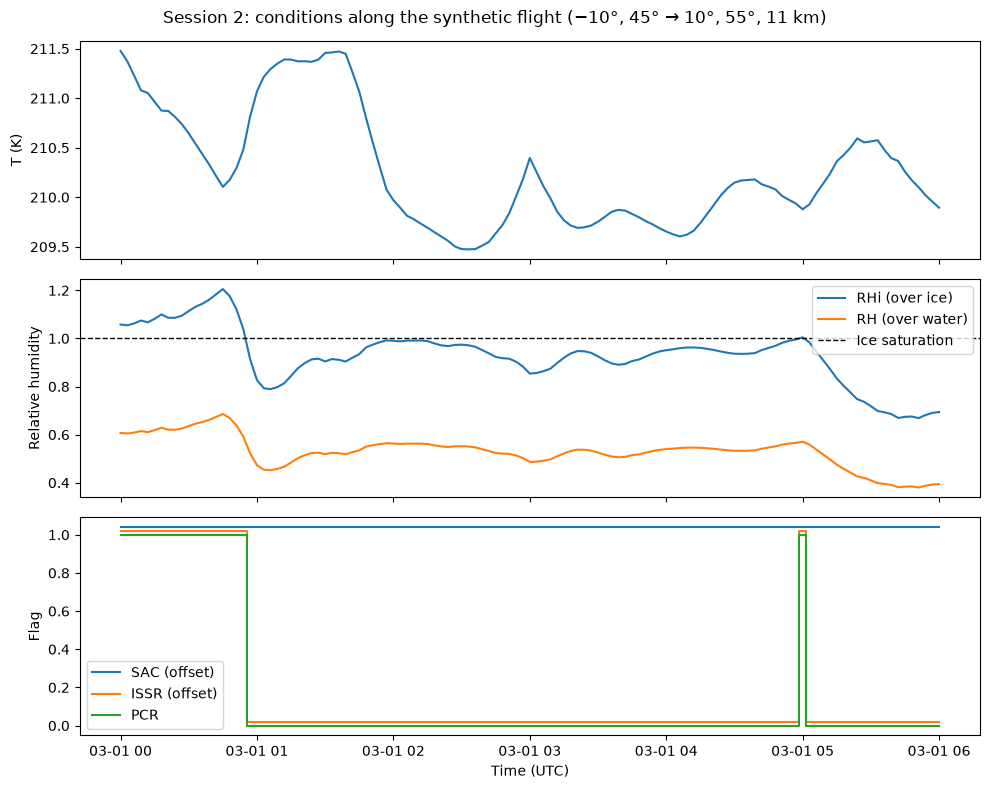

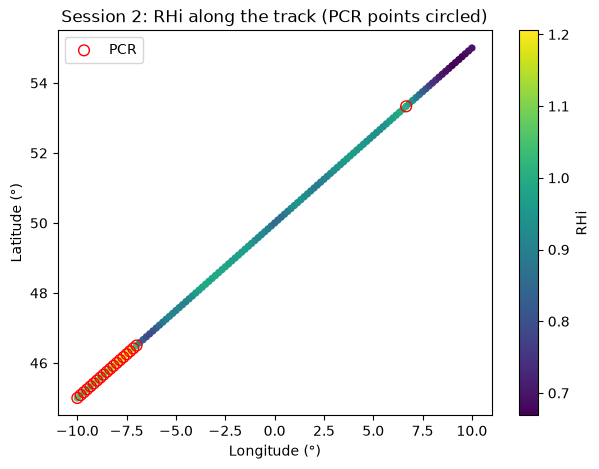

In [11]:
fig, axes = plt.subplots(3, 1, figsize=(10, 8), sharex=True)
axes[0].plot(s2["time"], s2["temperature_K"])
axes[0].set_ylabel("T (K)")
axes[1].plot(s2["time"], s2["rhi"], label="RHi (over ice)")
axes[1].plot(s2["time"], s2["rh"], label="RH (over water)")
axes[1].axhline(1.0, color="k", linestyle="--", linewidth=1, label="Ice saturation")
axes[1].set_ylabel("Relative humidity")
axes[1].legend()
axes[2].step(s2["time"], s2["SAC"] + 0.04, where="mid", label="SAC (offset)")
axes[2].step(s2["time"], s2["ISSR"] + 0.02, where="mid", label="ISSR (offset)")
axes[2].step(s2["time"], s2["PCR"], where="mid", label="PCR")
axes[2].set_ylabel("Flag")
axes[2].set_xlabel("Time (UTC)")
axes[2].legend()
fig.suptitle("Session 2: conditions along the synthetic flight (−10°, 45° → 10°, 55°, 11 km)")
plt.tight_layout()
fig.savefig(fig_dir / "session2_along_track.png", dpi=150, bbox_inches="tight")
plt.show()

fig, ax = plt.subplots(figsize=(7, 5))
sc = ax.scatter(s2["longitude"], s2["latitude"], c=s2["rhi"], cmap="viridis", s=18)
ax.scatter(s2.loc[pcr_flag, "longitude"], s2.loc[pcr_flag, "latitude"],
           facecolors="none", edgecolors="red", s=60, label="PCR")
fig.colorbar(sc, label="RHi")
ax.set_xlabel("Longitude (°)")
ax.set_ylabel("Latitude (°)")
ax.set_title("Session 2: RHi along the track (PCR points circled)")
ax.legend()
plt.show()

## Results

### Setup

**Session 1:** 20-point synthetic flight (0°, 50° → 5°, 52° at 11,000 m, 2022-03-01 00:00–01:00 UTC), ERA5 on 200/250/300 hPa, no humidity scaling.

**Session 2:** The 121-point, six-hour synthetic flight (−10°, 45° → 10°, 55° at 11 km, 2022-03-01 00:00–06:00 UTC, one point every 3 minutes) was evaluated with PCR on ERA5 (200–300 hPa, no humidity scaling).

### Checks

- No missing values in either ERA5 load (every hour checked).
- ISSR agrees with RHi > 1 at every point of the Session 2 flight; RHi/RH is 1.743–1.765 at these temperatures.
- This rebuilt notebook reproduces the saved Session 2 results (identical PCR at all 121 points).

### Findings

#### Session 1

- SAC met at all 20 points; ice supersaturation at none; no persistent-contrail conditions anywhere. Temperature ≈ 213.2 → 212.5 K.
- A valid baseline: this short flight did not cross persistent-contrail conditions.

#### Session 2

| Quantity | Value |
|---|---|
| Points evaluated (no missing data) | 121 / 121 |
| SAC satisfied | 121 / 121 |
| ISSR | 20 / 121 |
| PCR | 20 / 121 |
| Track length | 1810.4 km |
| Track length in PCR | 316.5 km (17.5%) |
| Flight time in PCR | 60 of 360 min |
| Along-track temperature | ≈ 209.5–211.5 K |
| Along-track RHi | 0.669 to 1.205 (mean 0.930, median 0.939) |

| Segment | Time (UTC) | Points | From → to | RHi range |
|---|---|---|---|---|
| 1 | 00:00–00:54 | 19 | (−10.0°, 45.0°) → (−7.0°, 46.5°) | 1.038–1.205 |
| 2 | 05:00 | 1 | (6.67°, 53.33°) | 1.005 |

Unlike Session 1, this trajectory crosses persistent-contrail conditions,
so PCR varies along the route. SAC is satisfied at every point (the
critical RH is 0: at ≈210 K the air is cold enough that SAC holds
regardless of humidity). **Ice supersaturation alone therefore determines
where persistent contrails occur** at this altitude and date.

The two segments are very different in character. Segment 1 is a coherent
supersaturated region: RHi rises to 1.205 and then drops sharply below
saturation just before 01:00. Segment 2 is a single point that only just
exceeds saturation (RHi = 1.005). Between them, RHi stays just below 1
for long stretches, peaking at about 0.99 around 02:00 and approaching
1.0 again just before 05:00.

#### Sensitivity to the saturation threshold

The PCR classification is fragile near the threshold:

- The highest RHi outside the PCR region is 0.996; the lowest inside it is 1.005.
- 13 of 121 points lie within ±0.02 of RHi = 1, 35 within ±0.05, and 79 within ±0.10.

A humidity error of only a few percent could therefore add or remove
substantial PCR length. Segment 2 is especially fragile. Segment 1's
core (RHi up to 1.2) is likely more robust. This motivates the later
uncertainty analysis.

### Interpretation

The pipeline works, and a realistic-length route does cross persistent-contrail conditions in this case: one coherent supersaturated region near the start and one marginal point near the end. Because the SAC holds everywhere at this altitude, ice supersaturation alone decides where persistent contrails form, and many points sit within a few percent of saturation. Both observations set up the rest of the project: comparing routes (Session 3) and testing humidity uncertainty (Sessions 5–7).

### Corrections

**Humidity variable (Session 1).** The first write-up quoted `rh` (0.39–0.50) as the persistence humidity. `rh` is relative to liquid water; persistence is decided by RHi (relative to ice), which is higher at these temperatures. The conclusion (no ice supersaturation) is unchanged.

**Missing ERA5 hour (Session 2).** The first load of the Session 2 meteorology returned all-NaN temperature
and humidity at 2022-03-01 04:00 UTC. Because PCR interpolates linearly in
time, this made 40 flight points (03:00–04:57) NaN. Counting
`(PCR > 0)` would have silently treated them as "no persistent contrail".
The gap was detected with an explicit NaN check. A fresh read showed the
source data was complete, so the corrupted 04:00 cache file was deleted
and regenerated. After the fix:

- There are 0 missing points.
- Previously valid points are unchanged (PCR identical; temperature
  within 7 × 10⁻⁶ K).

The gapped results are kept in `results/session2_pcr_along_track_gap_0400UTC.csv`
for the record. Re-reading without the cache (`cachestore=None`) was not
viable on this machine: ERA5 ARCO is stored on 137 model levels, and
interpolating global fields in memory exceeded the available RAM. The
disk cache processes one hour at a time.

**Flight speed.** The Session 2 flight was about a third of a real airliner's speed; Session 3 flies routes at 230 m/s, which changes exposure along the same line from 317 to 800 km.

### Limitations

- ERA5 is known to under-represent ice supersaturation at cruise levels;
  this baseline is deliberately unscaled (`humidity_scaling=None`).
- The flight samples each location at only one time, so this experiment
  cannot separate spatial from temporal variation. For example, it cannot
  say whether the supersaturated region near (−10°, 45°) persisted
  after 01:00 or moved.
- The flight has a single fixed altitude and a single date.